# Oil and Gas Production Analysis Using Python

## 1. Project Introduction

### 1.1 Background

Data analytics plays an important role in understanding production performance and identifying trends within the oil and gas industry. Production records contain valuable information that can be analysed to monitor production patterns, compare well performance, evaluate operator contributions, and identify unusual production behaviour.

This project analyses 2024 offshore oil and gas production records obtained from the U.S. Bureau of Safety and Environmental Enforcement (BSEE).

Using Python, the project applies data inspection, data quality assessment, exploratory data analysis (EDA), statistical analysis, and data visualization to extract meaningful insights from the production records.

### 1.2 Problem Statement

Oil and gas production datasets can contain large volumes of records, variations in production levels, zero-production periods, and differences in performance across wells and operators.

Without systematic analysis, identifying important production patterns and relationships can be difficult.

This project addresses this by examining the available production records and presenting the findings through statistical summaries, tables, and visualizations.

### 1.3 Project Objectives

The objectives of this project are to:

1. Examine the structure and characteristics of the production dataset.
2. Identify missing values, duplicate records, and potential data-quality issues.
3. Analyse monthly oil, gas, water, and injection production patterns.
4. Identify the highest-producing wells and operators.
5. Investigate relationships between oil, gas, and water production.
6. Calculate and analyse the Water-Oil Ratio (WOR).
7. Communicate important findings through clear and informative visualizations.

### 1.4 Research Questions

The analysis is guided by the following questions:

1. How did oil and gas production vary across the twelve months of 2024?
2. Which wells recorded the highest oil, gas, and water production?
3. Which operators contributed the highest recorded production volumes?
4. What relationships exist between oil, gas, and water production across wells?
5. What do the calculated Water-Oil Ratios reveal about well production patterns?
6. Are there unusual production records that may require further investigation?

### 1.5 Tools and Technologies

The project uses the following tools and libraries:

- **Python:** Programming language used for the analysis.
- **Pandas:** Data loading, manipulation, aggregation, and analysis.
- **NumPy:** Numerical operations and calculations.
- **Matplotlib:** Data visualization and graphical presentation.
- **Jupyter Notebook:** Interactive environment for conducting and documenting the analysis.

### 1.6 Project Scope

The analysis focuses on the available 2024 production records, with particular attention to monthly production trends, well-level performance, operator comparisons, production relationships, and Water-Oil Ratio analysis.

The findings describe patterns within the available dataset and should not be interpreted as establishing the operational or reservoir causes of those patterns.

## 2. Dataset Description and Source

### 2.1 Data Source

This project uses the 2024 Oil and Gas Operations Report (OGOR-A) dataset obtained from the U.S. Bureau of Safety and Environmental Enforcement (BSEE).

The dataset contains production records for oil and gas operations during 2024. It provides information on production volumes, well identification, operators, production dates, and other operational variables.

### 2.2 Dataset Overview

The dataset contains **62,836 records and 19 columns**. Each record represents a production entry in the dataset.

The analysis focuses on selected variables, including:

- `production_date`: The production period, recorded in YYYYMM format.
- `api_well_number`: A unique identifier for the well.
- `operator_name`: The company responsible for the operation.
- `days_on_prod`: Number of days recorded as producing.
- `monthly_oil`: Recorded monthly oil production volume.
- `monthly_gas`: Recorded monthly gas production volume.
- `monthly_water`: Recorded monthly water production volume.
- `injection_volume`: Recorded injection volume.
- `product_code`: Code identifying the product associated with a record.

### 2.3 Scope of the Analysis

The analysis examines production patterns across the 2024 reporting period, compares well and operator performance, investigates relationships between production variables, and evaluates water production relative to oil production using the Water-Oil Ratio (WOR).

*Note: Production volumes are discussed in the units recorded in the dataset. Specific measurement units are not assumed where they are not confirmed by the available metadata.*

## 3. Data Loading and Preparation

This section covers the libraries used in the analysis, loading the OGOR-A dataset into Python, and preparing the data for further exploration.

The dataset is imported using Pandas, while NumPy supports numerical operations and Matplotlib is used for data visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

columns = [
    "lease_number",
    "completion_name",
    "production_date",
    "days_on_prod",
    "product_code",
    "monthly_oil_volume",
    "monthly_gas_volume",
    "monthly_water_volume",
    "api_well_number",
    "well_status_code",
    "area_block",
    "operator_number",
    "operator_name",
    "field_name_code",
    "injection_volume",
    "production_interval_code",
    "first_production_date",
    "unit_agreement_number",
    "unit_allocation_suffix"
]

# Locate the dataset
possible_paths = [
    Path("data") / "ogora2024delimit.txt",
    Path("..") / "data" / "ogora2024delimit.txt"
]

data_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if data_path is None:
    raise FileNotFoundError("Dataset not found. Check your data folder.")

# Load the dataset
df = pd.read_csv(
    data_path,
    sep=",",
    header=None,
    names=columns,
    dtype=str
)

# Convert numerical columns
numeric_columns = [
    "days_on_prod",
    "monthly_oil_volume",
    "monthly_gas_volume",
    "monthly_water_volume",
    "injection_volume"
]

operator_production = df.groupby("operator_name")[[
    "monthly_oil_volume",
    "monthly_gas_volume",
    "monthly_water_volume"
]].sum()

operator_production.columns = [
    "total_oil",
    "total_gas",
    "total_water"
]

operator_production.head()

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df.shape)


(62836, 19)


In [3]:
operator_production.head()

,total_oil,total_gas,total_water
operator_name,,,
ANADARKO PETROLEUM CORPORATION,0000000000000000000000000000000000000000000000...,0000000000000000000000000000000000000000000000...,0000000000000000000000000000000000000000000000...
ANKOR ENERGY LLC,0000000000000000000000000000000000000000000000...,0000000000000000000000000000000000000000000000...,0000000000000000000000000000000000000000000000...
ARENA OFFSHORE LP,0000004080000011290000000030000050810000025660...,0000015710000048040000000000000034530000012640...,0000046680000080190000000220000098050000574710...
ARRAY PETROLEUM LLC,0000000000000000000000000000000000000000000000...,0000000000000000000000000000000000000000000000...,0000000000000000000000000000000000000000000000...
BEACON GROWTHCO OPERATING COMPANY LLC,0000000000000235510000376170002571640000405950...,0000000000000187880000577520003493400000257340...,0000000000000347980000022910000025720000022400...


In [4]:
df[[
    "monthly_oil_volume",
    "monthly_gas_volume",
    "monthly_water_volume"
]].dtypes

monthly_oil_volume      int64
monthly_gas_volume      int64
monthly_water_volume    int64
dtype: object

In [5]:
volume_columns = [
    "monthly_oil_volume",
    "monthly_gas_volume",
    "monthly_water_volume"
]

for col in volume_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [6]:
df[[
    "operator_name",
    "monthly_oil_volume",
    "monthly_gas_volume",
    "monthly_water_volume"
]].head(10)

,operator_name,monthly_oil_volume,monthly_gas_volume,monthly_water_volume
0,COX OPERATING LLC,0,0,0
1,COX OPERATING LLC,0,0,0
2,COX OPERATING LLC,0,0,0
3,COX OPERATING LLC,0,0,0
4,COX OPERATING LLC,0,0,0
5,COX OPERATING LLC,0,0,0
6,COX OPERATING LLC,0,0,0
7,COX OPERATING LLC,0,0,0
8,COX OPERATING LLC,0,0,0
9,COX OPERATING LLC,0,0,0


## 4. Data Understanding and Inspection

This section examines the structure and characteristics of the dataset before conducting detailed analysis. It involves reviewing the dataset dimensions, inspecting sample records, identifying variable data types, and generating descriptive statistics.

These steps provide an initial understanding of the available data and help identify areas that require further investigation.

## 4.1 Dataset Dimensions

In [7]:
print("Dataset shape:", df.shape)

Dataset shape: (62836, 19)


**Interpretation**

The dataset contains 62,836 rows and 19 columns. This indicates that the analysis is based on 62,836 production records and 19 variables containing information about well operations, production volumes, operators, and reporting periods.

## 4.2 Preview of Dataset Records

In [8]:
df.head()

,lease_number,completion_name,production_date,days_on_prod,product_code,monthly_oil_volume,monthly_gas_volume,monthly_water_volume,api_well_number,well_status_code,area_block,operator_number,operator_name,field_name_code,injection_volume,production_interval_code,first_production_date,unit_agreement_number,unit_allocation_suffix
0,00016,E002,202401,0,O,0,0,0,177190022500,12,WD 31,03151,COX OPERATING LLC,WD030,0,Q04,19720331,NaN,NaN
1,00016,E002D,202401,0,O,0,0,0,177190022500,12,WD 31,03151,COX OPERATING LLC,WD030,0,Q01,19610228,NaN,NaN
2,00016,E002Q,202401,0,O,0,0,0,177190022500,12,WD 31,03151,COX OPERATING LLC,WD030,0,Q64,NaN,NaN,NaN
3,00016,E002T,202401,0,O,0,0,0,177190022500,12,WD 31,03151,COX OPERATING LLC,WD030,0,Q65,NaN,NaN,NaN
4,00016,E016,202401,0,G,0,0,0,177194064700,13,WD 31,03151,COX OPERATING LLC,WD030,0,S03,20000605,NaN,NaN


**Interpretation**

The preview displays the first five records in the dataset, providing an initial view of the available variables and their corresponding values. It helps establish how production information is organised and provides an opportunity to identify the general structure of individual records.

## 4.3 Dataset Information and Data Types

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62836 entries, 0 to 62835
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   lease_number              62825 non-null  object
 1   completion_name           62820 non-null  object
 2   production_date           62836 non-null  object
 3   days_on_prod              62836 non-null  int64 
 4   product_code              62836 non-null  object
 5   monthly_oil_volume        62836 non-null  int64 
 6   monthly_gas_volume        62836 non-null  int64 
 7   monthly_water_volume      62836 non-null  int64 
 8   api_well_number           62836 non-null  object
 9   well_status_code          62836 non-null  object
 10  area_block                62836 non-null  object
 11  operator_number           62836 non-null  object
 12  operator_name             62836 non-null  object
 13  field_name_code           62836 non-null  object
 14  injection_volume      

**Interpretation**

The dataset information provides an overview of the 19 columns, their data types, and the number of non-null entries. The initial inspection helps identify how variables are stored and highlights fields that may require further examination during data preparation and quality assessment.

In [10]:
df.dtypes

lease_number                object
completion_name             object
production_date             object
days_on_prod                 int64
product_code                object
monthly_oil_volume           int64
monthly_gas_volume           int64
monthly_water_volume         int64
api_well_number             object
well_status_code            object
area_block                  object
operator_number             object
operator_name               object
field_name_code             object
injection_volume             int64
production_interval_code    object
first_production_date       object
unit_agreement_number       object
unit_allocation_suffix      object
dtype: object

**Interpretation**

The data types indicate how each column is represented in the DataFrame. Numerical variables, such as production volumes and days on production, are stored in numeric formats, while identification and categorical variables are stored as text (`object`). This distinction is important because it ensures that numerical variables can be used for calculations and statistical analysis, while categorical variables can be used for grouping and classification.

## 4.4 Descriptive Statistics

In [11]:
df.describe()

,days_on_prod,monthly_oil_volume,monthly_gas_volume,monthly_water_volume,injection_volume
count,62836.000000,62836.000000,6.283600e+04,62836.000000,6.283600e+04
mean,8.598813,10443.326119,1.092864e+04,6302.652444,3.330264e+03
std,12.908514,45734.124936,5.647630e+04,25929.361792,4.313239e+04
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00
25%,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00
50%,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00
75%,24.000000,611.000000,6.942500e+02,494.250000,0.000000e+00
max,31.000000,711866.000000,1.551124e+06,572660.000000,1.664516e+06


**Interpretation**

The descriptive statistics summarise the numerical variables using measures such as count, mean, standard deviation, minimum, maximum, and quartiles.

These statistics provide an initial understanding of the distribution and variability of production measurements. They also help identify unusually large values and differences in the scale of the numerical variables, which can guide further exploratory analysis.

## 5. Data Quality Assessment

In [12]:
df.isnull().sum()

lease_number                   11
completion_name                16
production_date                 0
days_on_prod                    0
product_code                    0
monthly_oil_volume              0
monthly_gas_volume              0
monthly_water_volume            0
api_well_number                 0
well_status_code                0
area_block                      0
operator_number                 0
operator_name                   0
field_name_code                 0
injection_volume                0
production_interval_code        0
first_production_date       21873
unit_agreement_number       46420
unit_allocation_suffix      46420
dtype: int64

**Interpretation**

The `df.isnull().sum()` operation identifies the total number of missing values in each column of the dataset. This provides an initial overview of data completeness and helps identify variables that may require further attention during data preparation.

### 5.1 Missing Values Assessment

Missing values occur when certain entries in a dataset are not recorded or available. Assessing missing values is an important step in evaluating data quality, as incomplete information may affect the accuracy and reliability of subsequent analysis.

This assessment examines the dataset to identify columns containing missing entries and determine the extent of missing information.


In [13]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage (%)": (df.isnull().sum() / len(df)) * 100
})

missing_summary = missing_summary.sort_values(
    by="Percentage (%)",
    ascending=False
)

missing_summary

,Missing Values,Percentage (%)
unit_allocation_suffix,46420,73.874849
unit_agreement_number,46420,73.874849
first_production_date,21873,34.809663
completion_name,16,0.025463
lease_number,11,0.017506
monthly_oil_volume,0,0.000000
monthly_gas_volume,0,0.000000
monthly_water_volume,0,0.000000
api_well_number,0,0.000000
product_code,0,0.000000


### Interpretation of Missing Values

The missing-value assessment revealed that `unit_allocation_suffix` and `unit_agreement_number` each contain approximately 73.87% missing values, while `first_production_date` has approximately 34.81% missing values.

In contrast, `completion_name` and `lease_number` contain very few missing records, representing less than 0.03% of the dataset each. The remaining variables have no missing values.

The high proportion of missing values in the unit-related fields may reflect incomplete administrative information rather than missing production measurements. Therefore, these fields were retained without imputation, as assigning artificial values could introduce misleading information.

Similarly, missing first production dates were not replaced because the analysis does not require estimating those dates.

Importantly, the key production variables used in this analysis contain no missing values, allowing the production analysis to proceed without imputing missing production measurements.

### 5.2 Product Code Distribution

The dataset contains multiple product codes representing different categories of production records. Examining their frequency helps establish the composition of the dataset and provides context for interpreting the production variables.

The distribution of product codes is examined using frequency counts and percentages.

In [14]:
product_code_summary = pd.DataFrame({
    "Record Count": df["product_code"].value_counts(),
    "Percentage (%)": (
        df["product_code"].value_counts(normalize=True) * 100
    )
})

product_code_summary

,Record Count,Percentage (%)
product_code,,
O,32126,51.126743
U,20773,33.059074
G,8257,13.140556
S,1679,2.672035
T,1,0.001591


### Interpretation of Product Code Distribution

The product-code analysis shows that code O represents the largest proportion of records, accounting for approximately 51.13% of the dataset. Code U follows with 33.06%, while G accounts for 13.14%.

Codes S and T occur less frequently, representing approximately 2.67% and 0.0016% of records, respectively.

This distribution indicates that the dataset is not evenly distributed across product codes. Therefore, the composition of the records should be considered when interpreting the overall production results.

The product-code labels are retained as recorded in the source dataset; their specific meanings should be confirmed using the official BSEE data documentation before assigning interpretations.

### 5.3 Duplicate Records Assessment

Duplicate records occur when identical rows appear more than once in a dataset. Their presence can lead to double-counting and may affect the accuracy of statistical summaries and analytical results.

This assessment checks for fully duplicated records across all columns to determine whether repeated entries exist in the dataset.

In [15]:
df.duplicated().sum()

0

### Interpretation of Duplicate Records

The duplicate-record assessment identified zero fully duplicated rows in the dataset.

This indicates that no two records are identical across all 19 columns. Therefore, no records were removed on the basis of full-row duplication.

However, the absence of fully duplicated records does not necessarily rule out repeated well identifiers or production dates, as a well may legitimately have multiple production records.

### 5.4 Production Date Distribution

The production date indicates the reporting month associated with each production record. Examining the distribution of records across the reporting months helps assess the consistency of monthly data coverage and identify variations in the number of records reported for each period.

This analysis counts the number of records associated with each production month and arranges the results chronologically.

In [16]:
df["production_date"].value_counts().sort_index()

production_date
202401    6133
202402    5170
202403    5179
202404    5173
202405    5177
202406    5169
202407    5168
202408    5165
202409    5160
202410    5160
202411    5095
202412    5087
Name: count, dtype: int64

**Interpretation**

The distribution shows that production records are available for all 12 months of 2024. January has the highest number of records, with 6,133, while December has the lowest, with 5,087. The remaining months contain between 5,095 and 5,179 records.

The higher record count in January indicates a variation in the number of reported records across the months. This difference should be considered when interpreting monthly production trends, as changes in record counts may influence aggregated production figures.

### Descriptive Statistics – Key Observations

The descriptive statistics reveal considerable variation in the production data. All five numerical variables have a median value of zero, indicating that at least half of the records contain zero values for each variable.

The mean values are considerably higher than the medians, suggesting that production volumes are unevenly distributed, with some records having substantially higher values than others.

Production days range from 0 to 31, which is consistent with monthly reporting.

These observations suggest the need to investigate zero production values and understand the distribution of the recorded production volumes before proceeding with further analysis.

### 5.5 Descriptive Statistics of Numerical Variables

Descriptive statistics provide a numerical summary of the dataset's production and operational variables. Measures such as the mean, standard deviation, minimum, maximum, and quartiles help reveal the distribution, spread, and variability of the recorded values.

This assessment examines the numerical variables to identify general patterns and potential irregularities that may require further investigation.

In [17]:
df[numeric_columns].describe()

,days_on_prod,monthly_oil_volume,monthly_gas_volume,monthly_water_volume,injection_volume
count,62836.000000,62836.000000,6.283600e+04,62836.000000,6.283600e+04
mean,8.598813,10443.326119,1.092864e+04,6302.652444,3.330264e+03
std,12.908514,45734.124936,5.647630e+04,25929.361792,4.313239e+04
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00
25%,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00
50%,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00
75%,24.000000,611.000000,6.942500e+02,494.250000,0.000000e+00
max,31.000000,711866.000000,1.551124e+06,572660.000000,1.664516e+06


**Interpretation**

The descriptive statistics show considerable variation across the numerical variables. All five variables have a median (50th percentile) of zero, indicating that at least half of the records contain zero values.

The mean values are higher than the medians, suggesting that the distributions are positively skewed, with some records having substantially higher values than others.

Production days range from 0 to 31, while monthly oil, gas, water, and injection volumes also show wide ranges between their minimum and maximum values. These observations highlight the need to examine zero values and production patterns more closely in subsequent analyses.

### 5.6 Zero-Value Assessment

Zero values in production datasets may represent periods when a well recorded no production or injection activity. Examining their frequency helps us understand the distribution of operational activity and distinguish genuine zero-production records from potential data-quality issues.

This assessment counts the zero values in each numerical variable to determine how frequently they occur across the dataset.

In [18]:
(df[numeric_columns] == 0).sum()

days_on_prod            41453
monthly_oil_volume      43094
monthly_gas_volume      42776
monthly_water_volume    44159
injection_volume        61963
dtype: int64

### Interpretation of Zero Values

The zero-value assessment revealed a substantial number of zero entries across the production and operational variables.

Monthly water volume recorded the highest number of zero entries among the three production-volume variables, with 44,159 records. Monthly oil and gas volumes recorded 43,094 and 42,776 zero entries, respectively.

Injection volume had 61,963 zero entries, while days on production recorded 41,453.

These zero values may reflect periods of no production, inactive wells, or operations where a particular production or injection activity was not recorded.

Rather than treating all zero values as errors, they are retained for further investigation to avoid removing potentially meaningful operational information.

### 5.7 Negative-Value Assessment

Negative values in production datasets may indicate data-entry errors, unusual reporting conditions, or other data-quality issues. Since production days and recorded production or injection volumes are generally expected to be non-negative, this assessment checks for negative entries across the numerical variables.

The objective is to identify any negative values that may require further investigation before proceeding with the analysis.

In [19]:
(df[numeric_columns] < 0).sum()

days_on_prod            0
monthly_oil_volume      0
monthly_gas_volume      0
monthly_water_volume    0
injection_volume        0
dtype: int64

### Interpretation of Negative Values

The negative-value assessment identified zero negative entries across the numerical production and operational variables examined.

This indicates that the dataset contains no negative values in these fields, reducing concerns about invalid negative production measurements within the variables assessed.

However, this check alone does not establish that every recorded value is operationally valid; additional consistency checks are still required.

### 5.8 Production-Day Validity Check

The `days_on_prod` variable records the number of days a well was reported as producing during a given reporting month. Since the dataset contains monthly production records for 2024, the recorded production days should not exceed the maximum number of calendar days in a month.

This assessment identifies records with more than 31 production days to check for potentially invalid entries.

In [20]:
(df["days_on_prod"] > 31).sum()

0

### Interpretation of Production Days

The consistency check identified zero records with more than 31 production days.

This indicates that all recorded production-day values fall within the maximum possible number of calendar days in a month.

The result suggests that the production-day variable does not contain values exceeding this basic monthly limit. However, further checks are necessary to examine the relationship between production days and recorded production volumes.

### 5.9 Zero Production Days with Positive Oil Production

A production record showing zero production days alongside a positive oil volume may indicate a potential inconsistency in the reported data.

This assessment identifies records where `days_on_prod` is zero while `monthly_oil_volume` is greater than zero. The results help evaluate the consistency between reported production days and oil production volumes.

In [21]:
(df["days_on_prod"].eq(0) & df["monthly_oil_volume"].gt(0)).sum()

0

### Interpretation of Zero Production Days and Positive Oil Production

The consistency check identified zero records where days on production was recorded as zero while monthly oil production was greater than zero.

This indicates consistency between the recorded production days and oil production for this particular condition.

The finding reduces concerns about oil production being reported without any corresponding production days in the records examined.

### 5.10 Positive Production Days with Zero Oil Production

A well may record production activity during a reporting month without recording any oil production. This may occur where the well produces other fluids, such as natural gas or water, or under other operational circumstances.

This assessment identifies records where `days_on_prod` is greater than zero while `monthly_oil_volume` is zero. The objective is to examine these records and determine whether they require further investigation.

In [22]:
(df["days_on_prod"].gt(0) & df["monthly_oil_volume"].eq(0)).sum()

1641

### Interpretation of Positive Production Days with Zero Oil Production

The assessment identified 1,641 records where days on production was greater than zero while monthly oil production was recorded as zero.

This finding indicates that recorded operational activity does not necessarily correspond to positive oil production in every reporting record.

Some of these records may represent periods of gas or water production without oil production, or other operational circumstances.

These records were retained because zero oil production does not automatically indicate invalid data. Their presence highlights the importance of considering individual production variables when interpreting operational performance.

# 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) involves examining the dataset to uncover meaningful patterns, relationships, trends, and variations within the recorded production data.

In this section, the analysis moves beyond data quality checks to investigate oil, gas, and water production patterns, compare well and operator performance, and examine relationships between important production variables.

The findings will help provide a better understanding of production behaviour and demonstrate how data analysis can support petroleum engineering decisions.

### 6.1 Monthly Production Trends

Analysing monthly production trends helps reveal how oil, gas, and water production vary over time. Changes in production volumes may reflect differences in well activity, operational conditions, or other production-related factors.

In this analysis, monthly production volumes are aggregated across all records to examine the overall production pattern throughout 2024.

The results will be used to identify months with relatively high or low production and compare the behaviour of the three production variables.

### **Monthly Oil and Gas Production**

In [23]:
monthly_production = df.groupby("production_date").agg(
    total_oil=("monthly_oil_volume", "sum"),
    total_gas=("monthly_gas_volume", "sum")
)

monthly_production

,total_oil,total_gas
production_date,,
202401,54389450,61175454
202402,52667184,56305118
202403,55955176,55946856
202404,55791282,58296677
202405,55902618,55369683
202406,54632345,56775058
202407,56845228,60181436
202408,57156809,60724077
202409,48320873,49616309


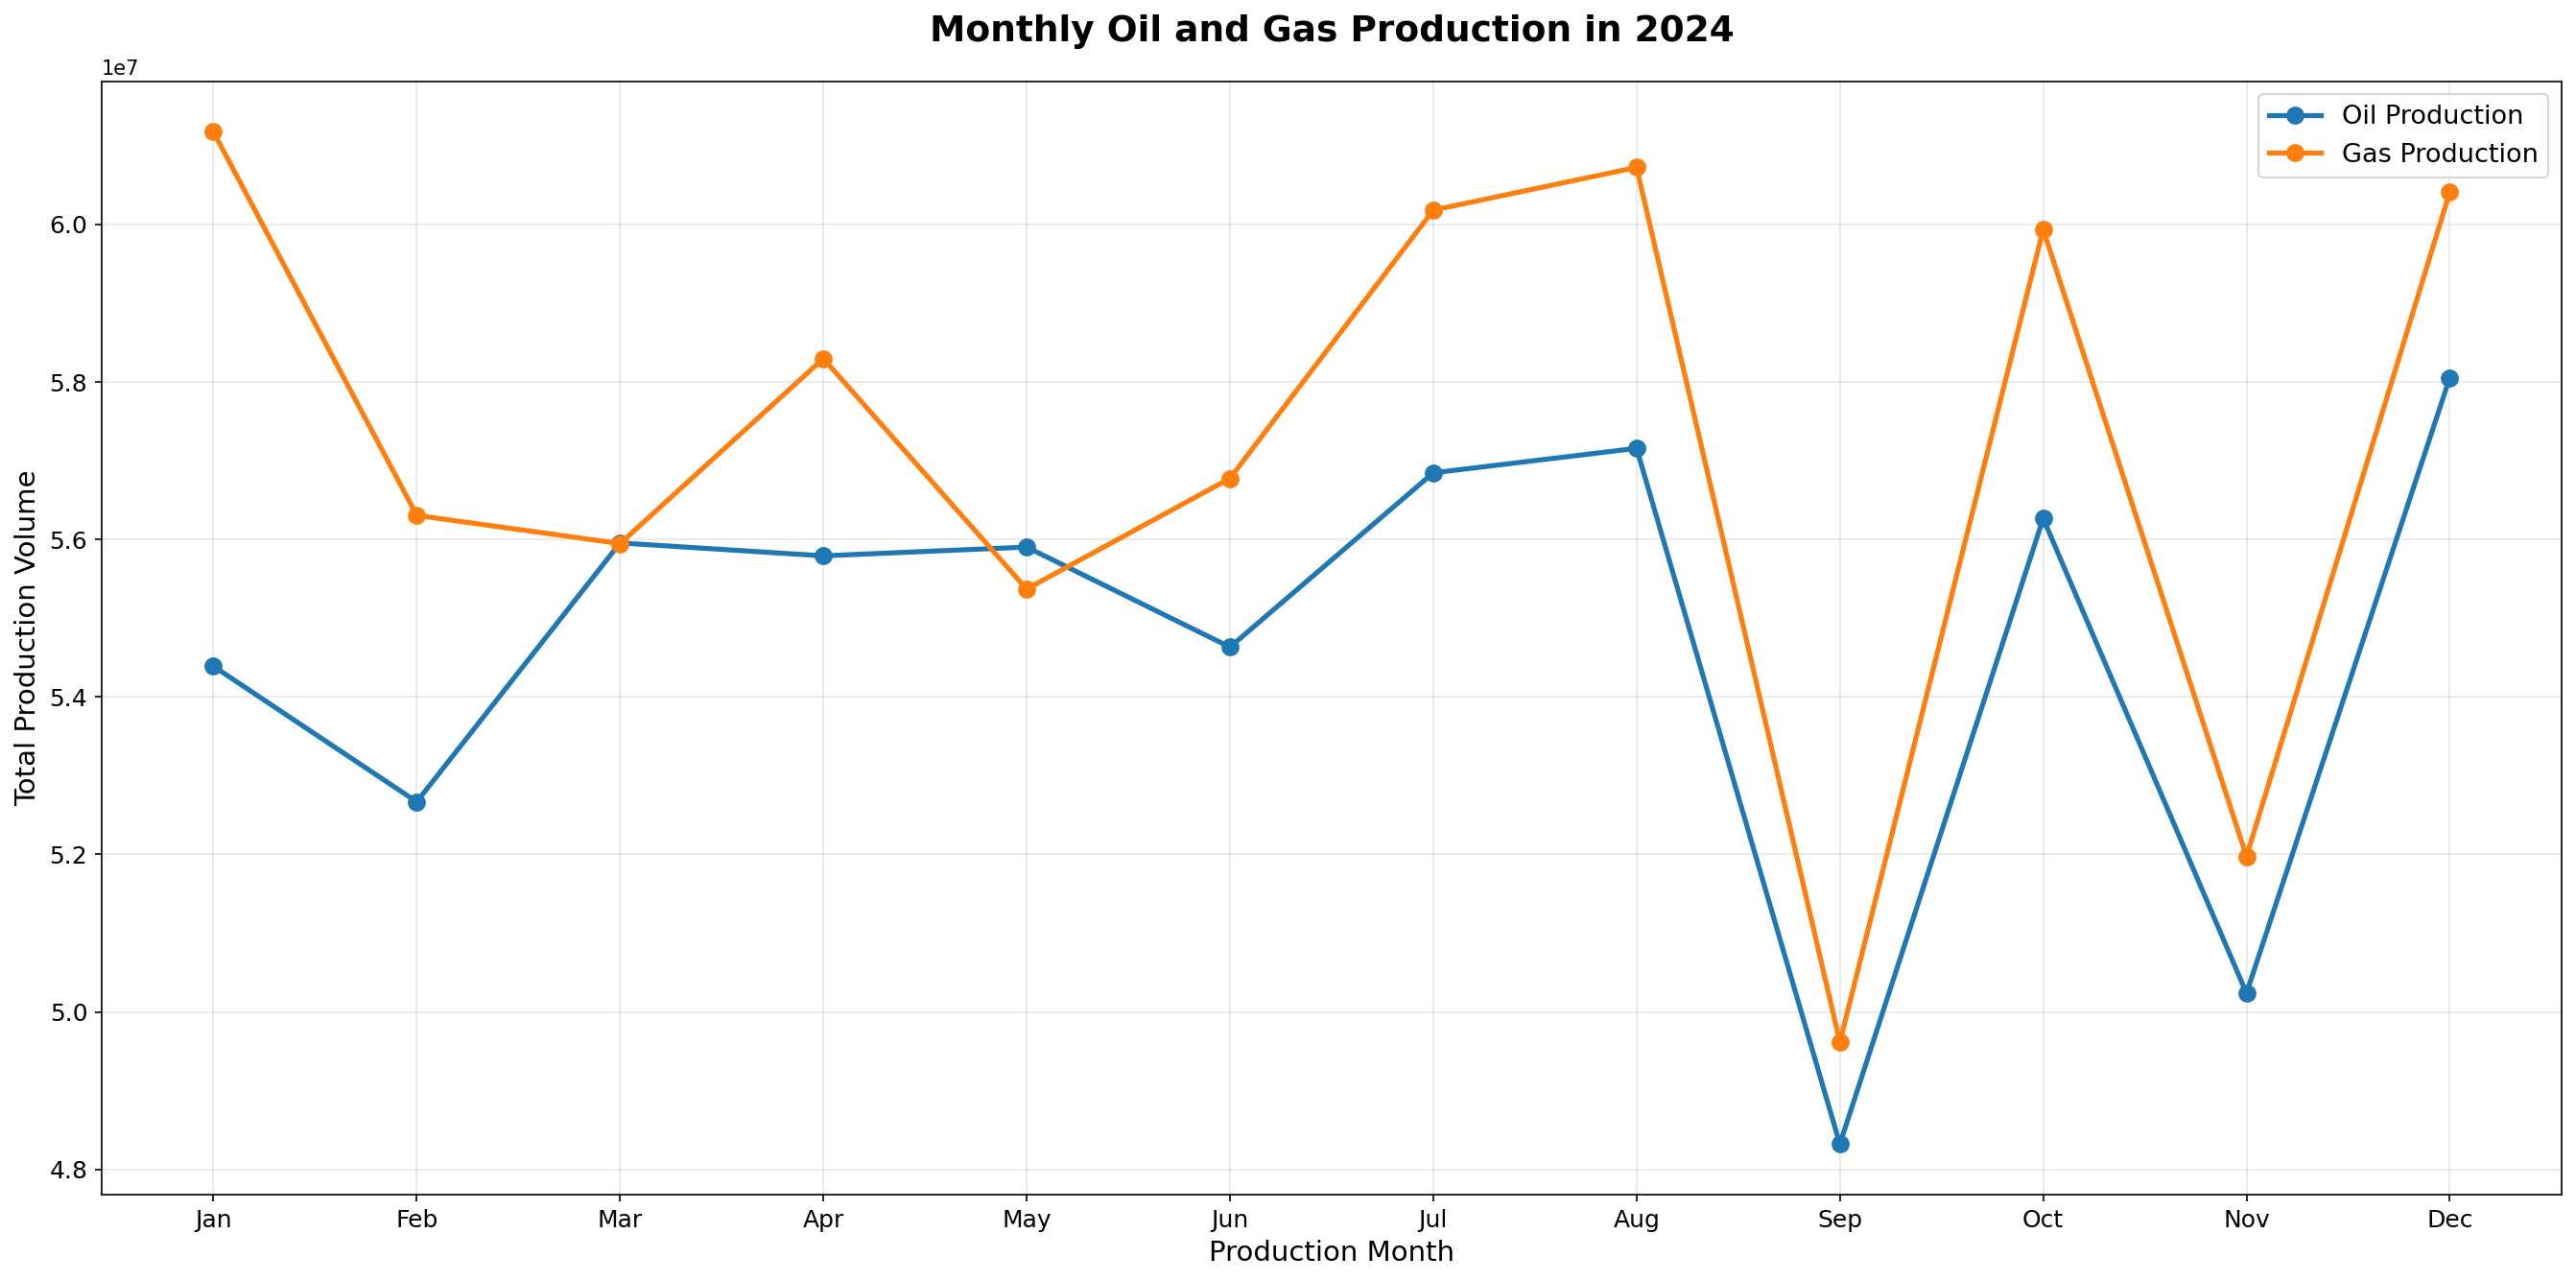

In [24]:
fig, ax = plt.subplots(figsize=(18, 9), dpi=150)

ax.plot(
    monthly_production.index,
    monthly_production["total_oil"],
    marker="o",
    markersize=8,
    linewidth=2.5,
    label="Oil Production"
)

ax.plot(
    monthly_production.index,
    monthly_production["total_gas"],
    marker="o",
    markersize=8,
    linewidth=2.5,
    label="Gas Production"
)

ax.set_title(
    "Monthly Oil and Gas Production in 2024",
    fontsize=18,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Production Month", fontsize=14)
ax.set_ylabel("Total Production Volume", fontsize=14)

ax.set_xticks(range(len(monthly_production.index)))
ax.set_xticklabels(
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    fontsize=12
)

ax.tick_params(axis="y", labelsize=12)
ax.legend(fontsize=13)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### **Interpretation**

The monthly production analysis reveals noticeable fluctuations in recorded oil and gas volumes throughout 2024.

- **Oil production:** December recorded the highest monthly total, approximately 58.05 million, while September recorded the lowest, approximately 48.32 million.
- **Gas production:** August recorded the highest monthly total, approximately 60.72 million, while September recorded the lowest, approximately 49.62 million.
- **September decline:** Both oil and gas production experienced a substantial decline in September, followed by a recovery in October.

The simultaneous decline in oil and gas production during September is a notable pattern in the dataset. However, further operational information would be required to establish the reasons behind this change.

Overall, the analysis demonstrates the importance of monitoring monthly production trends to identify periods of significant variation and support further investigation.

### **Monthly Water Production and Injection**

In [25]:
monthly_water_injection = df.groupby("production_date").agg(
    total_water=("monthly_water_volume", "sum"),
    total_injection=("injection_volume", "sum")
)

monthly_water_injection

,total_water,total_injection
production_date,,
202401,33721753,16478830
202402,30187516,15662977
202403,33308166,16299667
202404,32241622,15910242
202405,34140565,18043860
202406,32846127,16327191
202407,34309947,19445160
202408,35490860,20075642
202409,28129357,15014683


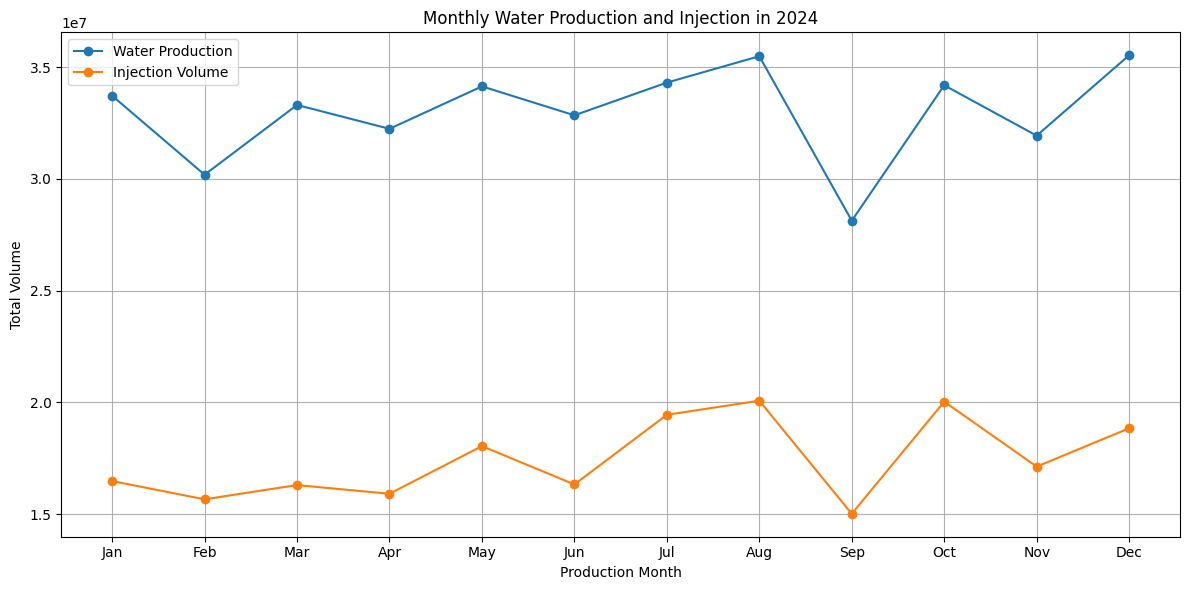

In [26]:
plt.figure(figsize=(12, 6))

plt.plot(monthly_water_injection.index,
         monthly_water_injection["total_water"],
         marker="o", label="Water Production")

plt.plot(monthly_water_injection.index,
         monthly_water_injection["total_injection"],
         marker="o", label="Injection Volume")

plt.title("Monthly Water Production and Injection in 2024")
plt.xlabel("Production Month")
plt.ylabel("Total Volume")
plt.legend()
plt.grid(True)

plt.xticks(
    range(len(monthly_water_injection.index)),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.tight_layout()
plt.show()

### **Interpretation**

The monthly analysis reveals variations in both recorded water production and injection volumes throughout 2024.

- **Water production:** December recorded the highest monthly water production, approximately 35.53 million units, while September recorded the lowest, approximately 28.13 million units.
- **Injection volume:** August recorded the highest injection volume, approximately 20.08 million units, while September recorded the lowest, approximately 15.01 million units.
- **September decline:** Both water production and injection volumes reached their lowest recorded levels in September, consistent with the decline observed in monthly oil and gas production.

The simultaneous decline across these production variables is a notable observation. However, the available data does not establish whether the changes resulted from reduced well activity, operational conditions, or other factors.

Monitoring water production alongside injection volumes is important when examining production and injection patterns. Further operational and reservoir information would be needed to interpret the relationship more fully.

### **Monthly Average Production Days**

In [27]:
monthly_days = df.groupby("production_date").agg(
    average_production_days=("days_on_prod", "mean")
)

monthly_days

,average_production_days
production_date,
202401,7.898908
202402,8.464797
202403,8.533694
202404,8.527354
202405,9.101603
202406,8.949313
202407,9.034443
202408,9.046854
202409,7.178876


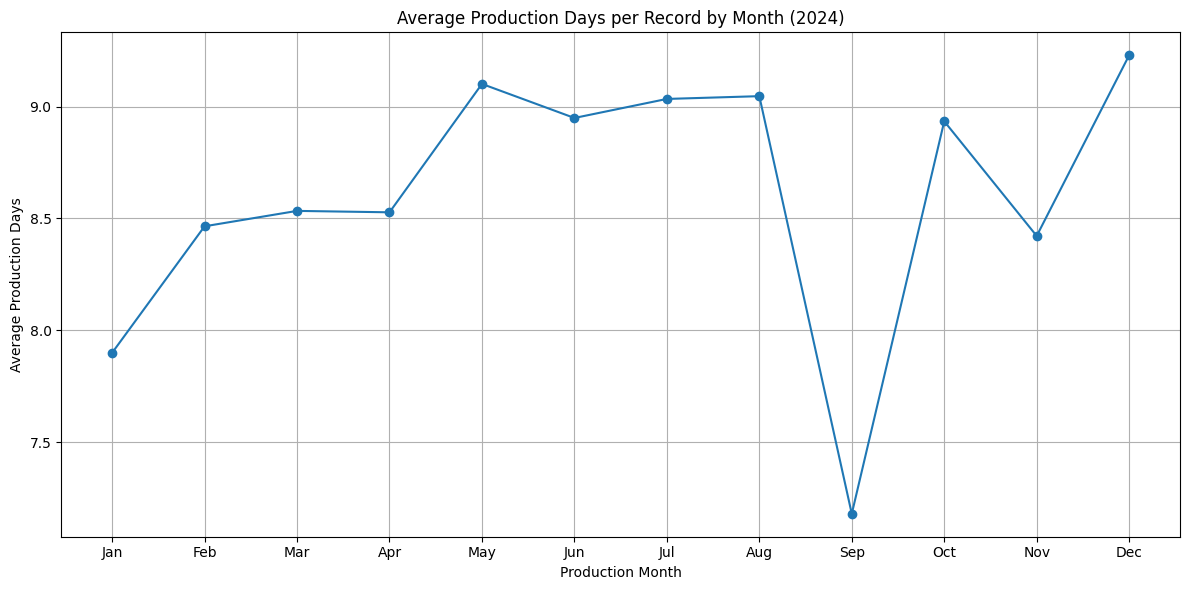

In [28]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_days.index,
    monthly_days["average_production_days"],
    marker="o"
)

plt.title("Average Production Days per Record by Month (2024)")
plt.xlabel("Production Month")
plt.ylabel("Average Production Days")
plt.xticks(
    range(len(monthly_days.index)),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
plt.grid(True)
plt.tight_layout()
plt.show()

### **Interpretation**

The analysis shows variations in the average number of production days recorded per reporting record across the twelve months of 2024.

- **Highest average:** December recorded the highest average production duration of approximately 9.23 days per record.
- **Lowest average:** September recorded the lowest average of approximately 7.18 days per record.
- **September observation:** The reduction in average production days coincides with the decline in oil, gas, water and injection volumes observed during the same month.

This pattern suggests that differences in recorded production days may be relevant when examining monthly production fluctuations. However, the averages represent production days per reporting record and should not be interpreted as the average operating duration of an individual well.

Further investigation using well-level operating records would help establish how production-day variations relate to changes in production volumes.

### **Monthly Water-Oil Ratio (WOR)**

In [29]:
monthly_wor = (
    monthly_water_injection["total_water"] /
    monthly_production["total_oil"]
)

monthly_wor

production_date
202401    0.620005
202402    0.573175
202403    0.595265
202404    0.577897
202405    0.610715
202406    0.601221
202407    0.603568
202408    0.620938
202409    0.582137
202410    0.607652
202411    0.635677
202412    0.612078
dtype: float64

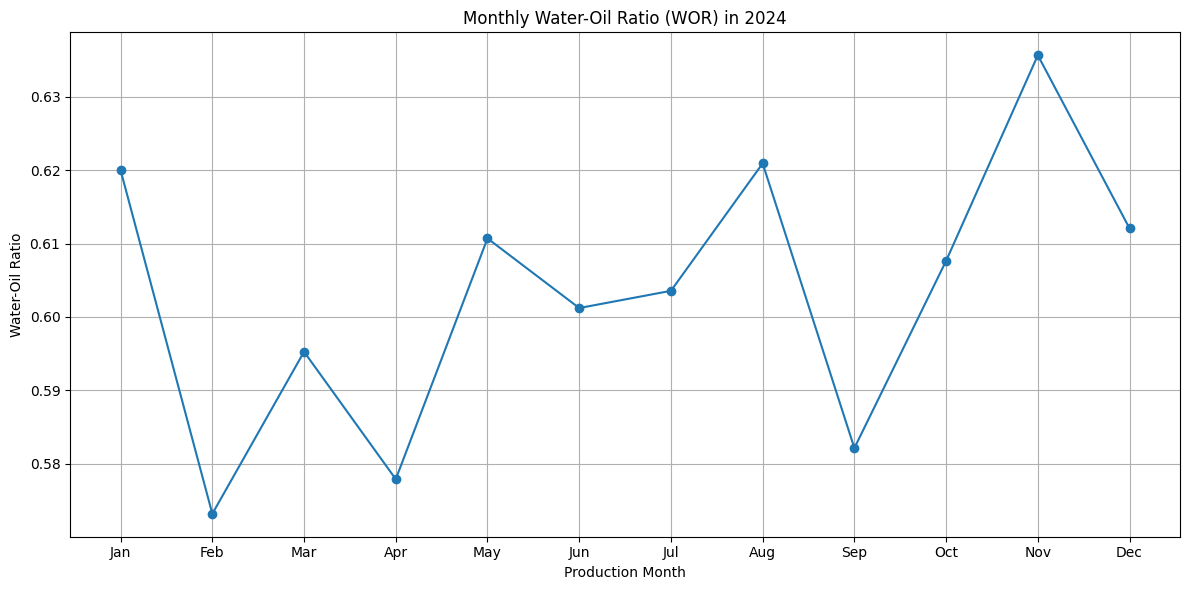

In [30]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_wor.index,
    monthly_wor.values,
    marker="o"
)

plt.title("Monthly Water-Oil Ratio (WOR) in 2024")
plt.xlabel("Production Month")
plt.ylabel("Water-Oil Ratio")
plt.xticks(
    range(len(monthly_wor.index)),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
plt.grid(True)
plt.tight_layout()
plt.show()

### **Interpretation**

The monthly Water-Oil Ratio (WOR) analysis examines the relationship between recorded water and oil production volumes throughout 2024.

- **Highest WOR:** November recorded the highest monthly WOR of approximately 0.6357.
- **Lowest WOR:** February recorded the lowest monthly WOR of approximately 0.5732.
- **September:** The monthly WOR was approximately 0.5821, despite September recording the lowest monthly oil and water production volumes.

The results show that the proportion of water production relative to oil production varied across the reporting period. Although September recorded lower production volumes, its WOR was not the lowest, demonstrating that production volume and WOR provide different information.

Monitoring monthly WOR can help identify changes in water production relative to oil production. However, monthly aggregate ratios should be interpreted alongside well-level production data because they may conceal differences between individual wells.

### 6.2 Well-Level Production Performance

This analysis examines production performance at the individual well level. Production records are grouped by API well number to identify the ten wells with the highest recorded oil, gas, and water production during 2024.

Comparing these wells helps highlight differences in production contribution across the dataset.

### Top 10 Oil-Producing Wells

In [31]:
well_production = df.groupby("api_well_number").agg(
    total_oil=("monthly_oil_volume", "sum")
)

well_production.head()

,total_oil
api_well_number,
012032016500,0
012032027100,0
012032029300,880
012032030900,0
177000000600,0


In [32]:
top_10_oil_wells = well_production.sort_values(
    by="total_oil",
    ascending=False
).head(10)

top_10_oil_wells

,total_oil
api_well_number,
608174144500,8166097
608174101101,5882419
608054005400,5644063
608174133000,5414667
608114070600,5350210
608124006001,5217804
608174132800,4957222
608174133900,4925348
608174119802,4875798


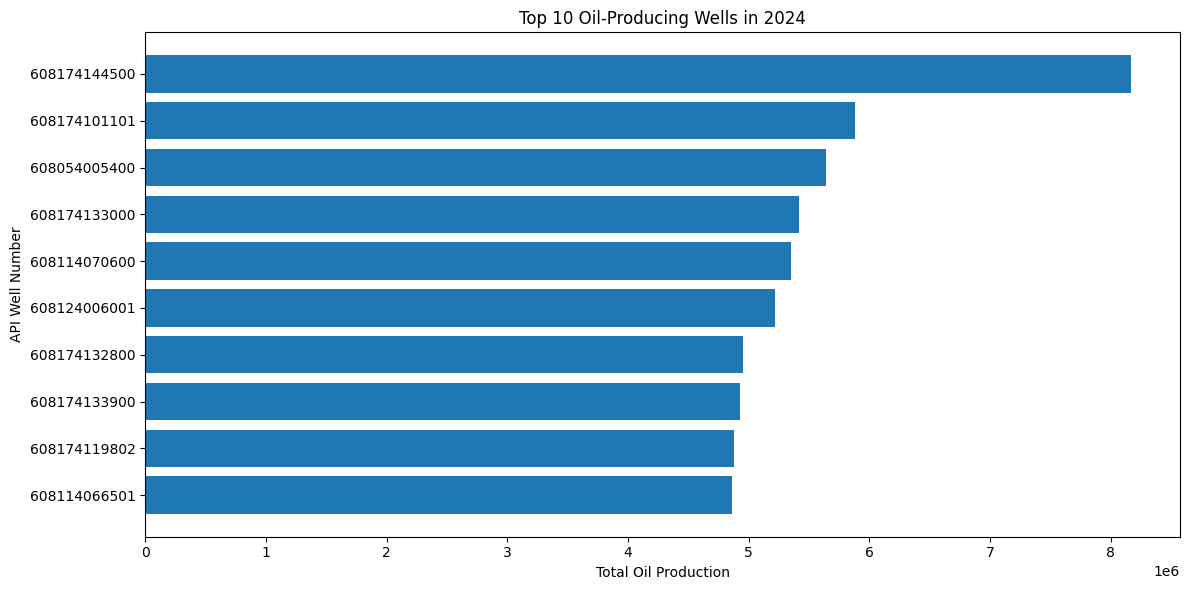

In [33]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_oil_wells.index.astype(str),
    top_10_oil_wells["total_oil"]
)

plt.title("Top 10 Oil-Producing Wells in 2024")
plt.xlabel("Total Oil Production")
plt.ylabel("API Well Number")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### **Interpretation**

The analysis identifies the ten wells with the highest recorded oil production during 2024.

- **Top-performing well:** API well number `608174144500` recorded the highest oil production, with a total of 8,166,097.
- The ranking highlights differences in oil production contribution among the wells in the dataset.
- Identifying high-producing wells helps highlight major contributors to recorded production and provides a basis for comparing individual well performance.

The results represent cumulative production over the reporting period and do not, on their own, explain the geological or operational reasons behind differences in well performance.

### Top 10 Gas-Producing Wells

In [34]:
well_gas = df.groupby("api_well_number").agg(
    total_gas=("monthly_gas_volume", "sum")
)

well_gas.head()

,total_gas
api_well_number,
012032016500,1141
012032027100,0
012032029300,1892672
012032030900,0
177000000600,81643


In [35]:
top_10_gas_wells = well_gas.sort_values(
    by="total_gas",
    ascending=False
).head(10)

top_10_gas_wells

,total_gas
api_well_number,
608164046801,16414218
608114072600,16334195
608114066501,13666285
608174129300,9152656
608074032700,8935031
608074008201,8483471
608114077500,7624800
608164046700,7139759
177164035900,6500042


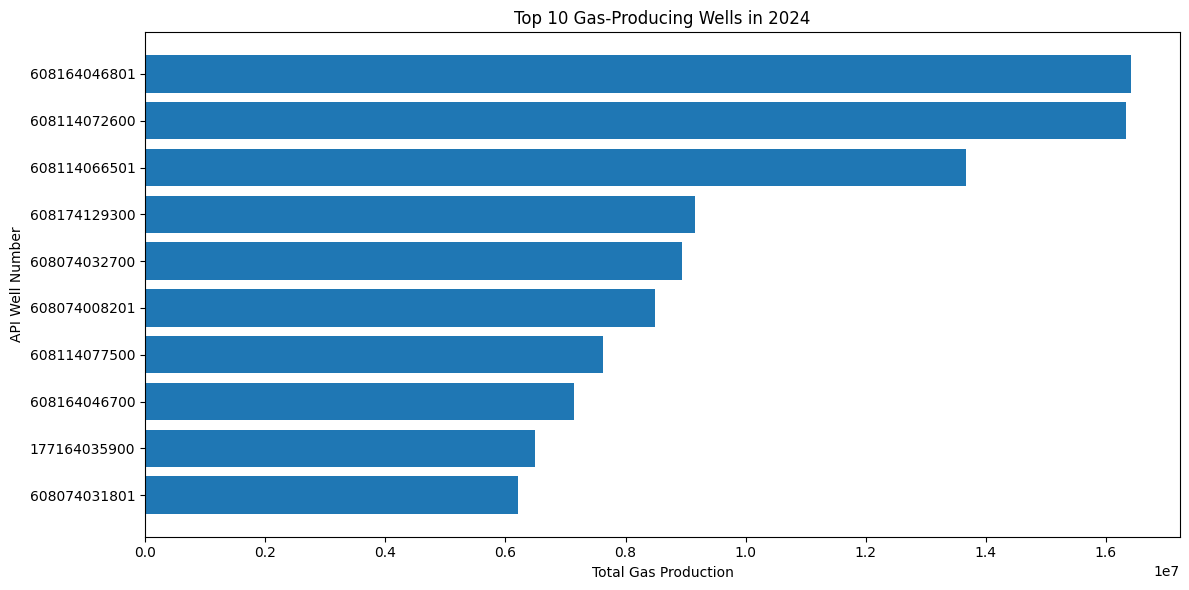

In [36]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_gas_wells.index.astype(str),
    top_10_gas_wells["total_gas"]
)

plt.title("Top 10 Gas-Producing Wells in 2024")
plt.xlabel("Total Gas Production")
plt.ylabel("API Well Number")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### **Interpretation**

The analysis identifies the ten wells with the highest recorded gas production during 2024.

- **Top-performing well:** API well number `608164046801` recorded the highest gas production, with a total of 16,414,218.
- **Second-highest well:** API well number `608114072600` recorded 16,334,195.
- The results highlight differences in gas production contribution across individual wells.
- Identifying the leading gas-producing wells helps assess their contribution to overall production and compare well performance.

These results represent cumulative gas production during the reporting period. They do not independently explain the geological or operational factors responsible for differences in gas production.

### Top 10 Water-Producing Wells

In [37]:
well_water = df.groupby("api_well_number").agg(
    total_water=("monthly_water_volume", "sum")
)

top_10_water_wells = well_water.sort_values(
    by="total_water",
    ascending=False
).head(10)

top_10_water_wells

,total_water
api_well_number,
608174104800,5165600
608174099800,4190993
608074009002,4162246
608174143800,3933799
608174122900,3901855
608124006200,3859396
608174108600,3669514
608174132900,3499808
608174109103,3426263


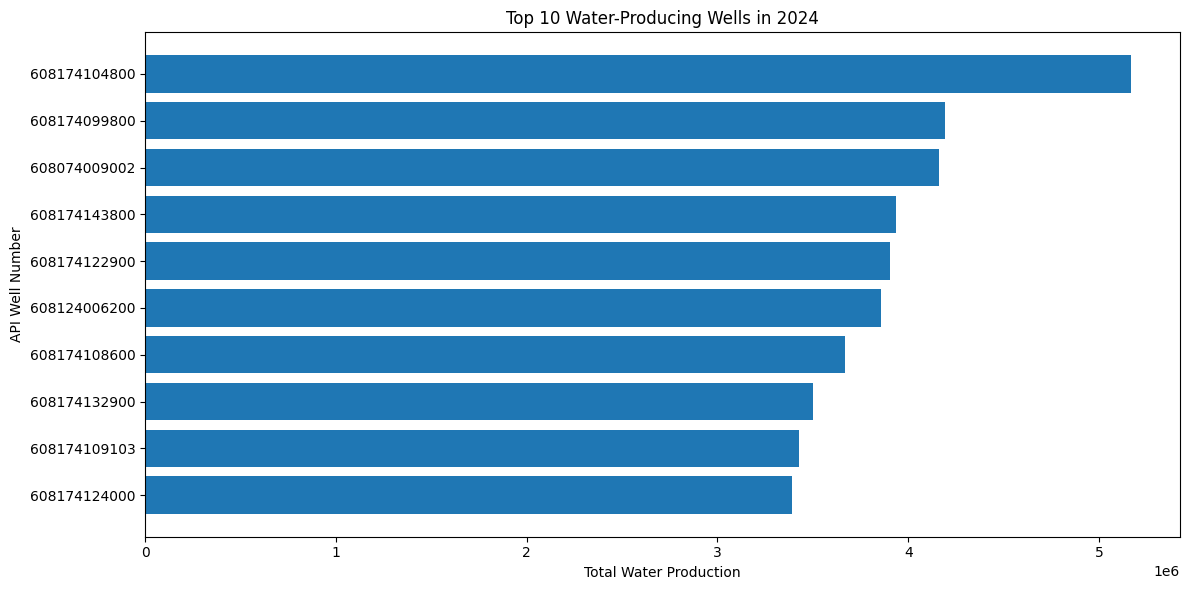

In [38]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_water_wells.index.astype(str),
    top_10_water_wells["total_water"]
)

plt.title("Top 10 Water-Producing Wells in 2024")
plt.xlabel("Total Water Production")
plt.ylabel("API Well Number")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### **Interpretation**

The analysis identifies the ten wells with the highest recorded water production during 2024.

- **Top-performing well:** API well number `608174104800` recorded the highest water production, with a total of 5,165,600.
- **Second-highest well:** API well number `608174099800` recorded 4,190,993.
- The ranking highlights differences in water production contribution across individual wells.
- Identifying wells with high water production is important for monitoring water handling requirements and understanding the relationship between water and hydrocarbon production.

High water production does not necessarily indicate poor well performance. The results should be considered alongside oil production, gas production, and water-oil ratio to obtain a more complete understanding of individual well performance.

### 6.3 Operator-Level Production Performance

This section examines production performance across different operators by aggregating recorded oil, gas, and water production. The analysis identifies the top ten operators for each production category and highlights their contributions to the overall recorded production during 2024.

In [39]:
operator_production = df.groupby("operator_name").agg(
    total_oil=("monthly_oil_volume", "sum"),
    total_gas=("monthly_gas_volume", "sum"),
    total_water=("monthly_water_volume", "sum")
)

operator_production.head()

,total_oil,total_gas,total_water
operator_name,,,
ANADARKO PETROLEUM CORPORATION,62274557,53813302,21083678
ANKOR ENERGY LLC,0,0,0
ARENA OFFSHORE LP,8454987,22538514,56596510
ARRAY PETROLEUM LLC,991398,3040261,5419676
BEACON GROWTHCO OPERATING COMPANY LLC,5590608,7763428,1154202


### Top 10 Oil-Producing Operators

In [40]:
top_10_oil_operators = operator_production.sort_values(
    by="total_oil",
    ascending=False
).head(10)

top_10_oil_operators

,total_oil,total_gas,total_water
operator_name,,,
SHELL OFFSHORE INC.,171703409,167434308,54396347
BP EXPLORATION & PRODUCTION INC,143525193,87506938,65339272
ANADARKO PETROLEUM CORPORATION,62274557,53813302,21083678
CHEVRON USA INC,55483282,37269893,18854495
MURPHY EXPLORATION & PRODUCTION COMPANY - USA,38903285,56059087,9144870
LLOG EXPLORATION OFFSHORE LLC,27347442,33756353,8154212
UNION OIL COMPANY OF CALIFORNIA,22217880,5304255,1339743
HESS CORPORATION,16941848,28764308,9569370
TALOS QN EXPLORATION LLC,15356770,29570177,7711810


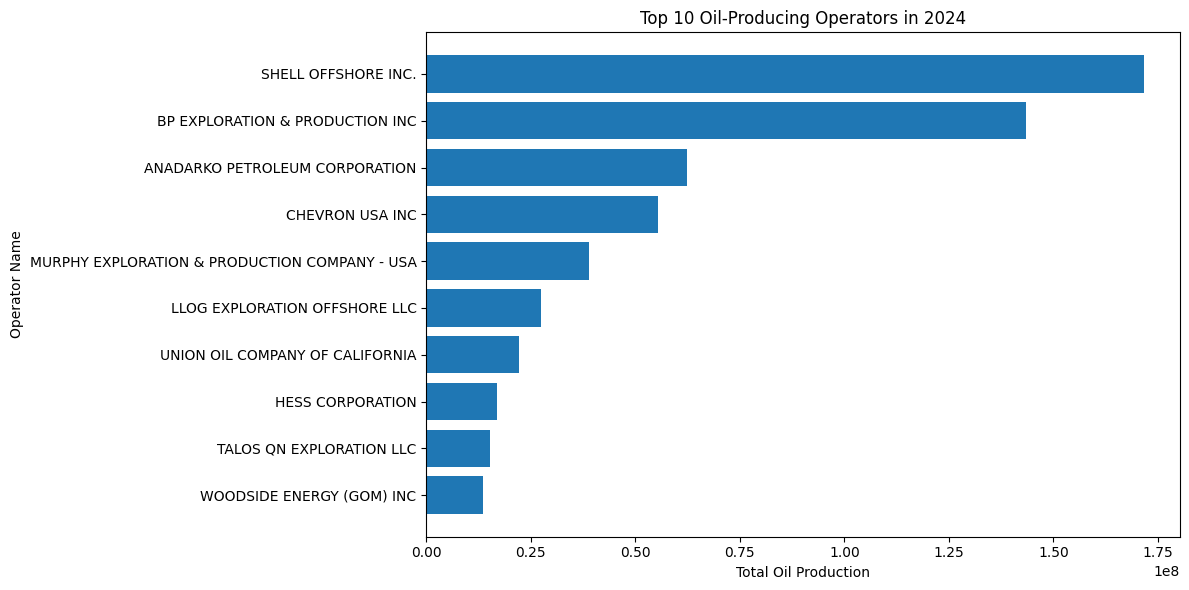

In [41]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_oil_operators.index,
    top_10_oil_operators["total_oil"]
)

plt.title("Top 10 Oil-Producing Operators in 2024")
plt.xlabel("Total Oil Production")
plt.ylabel("Operator Name")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Interpretation**

The analysis identifies the ten operators with the highest recorded oil production during 2024.

- **Top-performing operator:** Shell Offshore Inc. recorded the highest oil production, with a total of 171,703,409.
- The ranking highlights differences in oil production contributions among the operators.
- Identifying the leading oil-producing operators helps show which companies contributed most significantly to the recorded oil production in the dataset.

These figures represent cumulative production during the reporting period and do not independently explain the operational or geological factors behind the differences.

### Top 10 Gas-Producing Operators

In [42]:
top_10_gas_operators = operator_production.sort_values(
    by="total_gas",
    ascending=False
).head(10)

top_10_gas_operators

,total_oil,total_gas,total_water
operator_name,,,
SHELL OFFSHORE INC.,171703409,167434308,54396347
BP EXPLORATION & PRODUCTION INC,143525193,87506938,65339272
MURPHY EXPLORATION & PRODUCTION COMPANY - USA,38903285,56059087,9144870
ANADARKO PETROLEUM CORPORATION,62274557,53813302,21083678
CHEVRON USA INC,55483282,37269893,18854495
LLOG EXPLORATION OFFSHORE LLC,27347442,33756353,8154212
TALOS QN EXPLORATION LLC,15356770,29570177,7711810
HESS CORPORATION,16941848,28764308,9569370
TALOS PETROLEUM LLC,7414133,24271108,8921988


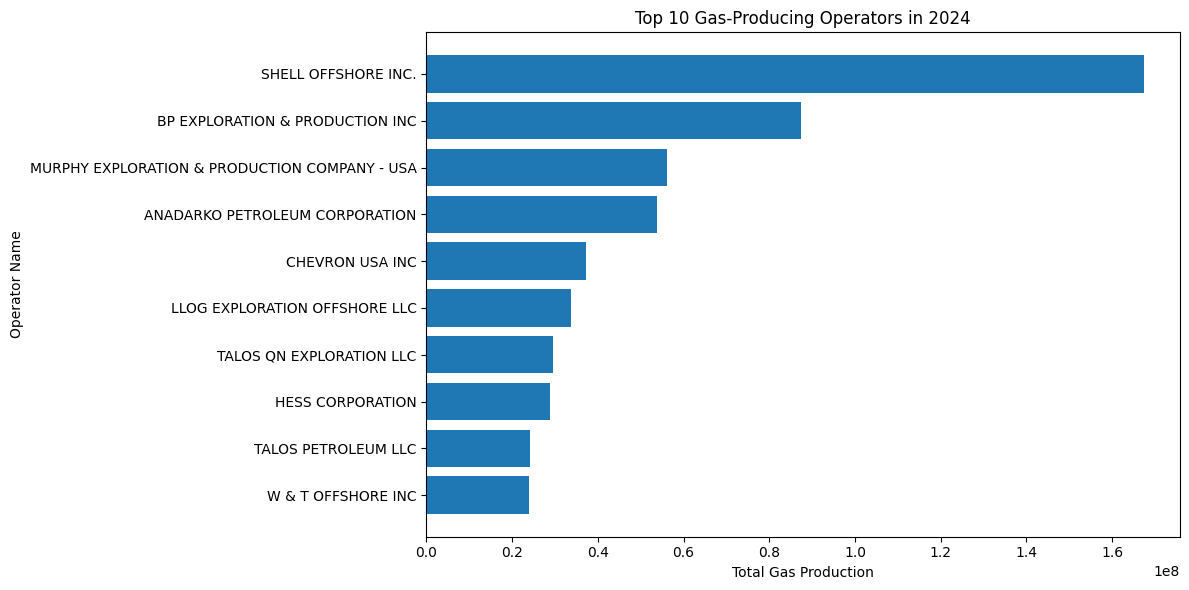

In [43]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_gas_operators.index,
    top_10_gas_operators["total_gas"]
)

plt.title("Top 10 Gas-Producing Operators in 2024")
plt.xlabel("Total Gas Production")
plt.ylabel("Operator Name")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Interpretation:**

The analysis identifies the top 10 operators with the highest total gas production in 2024.

Shell Offshore Inc. recorded the highest gas production, with a total of 167,434,308, followed by BP Exploration & Production Inc. with 87,506,938. Murphy Exploration & Production Company - USA ranked third with 56,059,087.

The results highlight the differences in gas production contributions among operators. Shell Offshore Inc. recorded a significantly higher gas production volume than the other operators in the top 10.

These figures represent cumulative production volumes for 2024 and do not independently explain the factors responsible for the differences in production performance.

### Top 10 Water-Producing Operators

This section examines water production across different operators. Identifying operators with the highest recorded water production can help provide an overview of water production patterns within the dataset.

In [44]:
top_10_water_operators = operator_production.sort_values(
    by="total_water",
    ascending=False
).head(10)

top_10_water_operators

,total_oil,total_gas,total_water
operator_name,,,
BP EXPLORATION & PRODUCTION INC,143525193,87506938,65339272
ARENA OFFSHORE LP,8454987,22538514,56596510
SHELL OFFSHORE INC.,171703409,167434308,54396347
CANTIUM LLC,5680745,5620788,22113031
ANADARKO PETROLEUM CORPORATION,62274557,53813302,21083678
CHEVRON USA INC,55483282,37269893,18854495
GOM SHELF LLC,3259467,9876215,17969945
W & T OFFSHORE INC,4582795,23866098,14833669
HESS CORPORATION,16941848,28764308,9569370


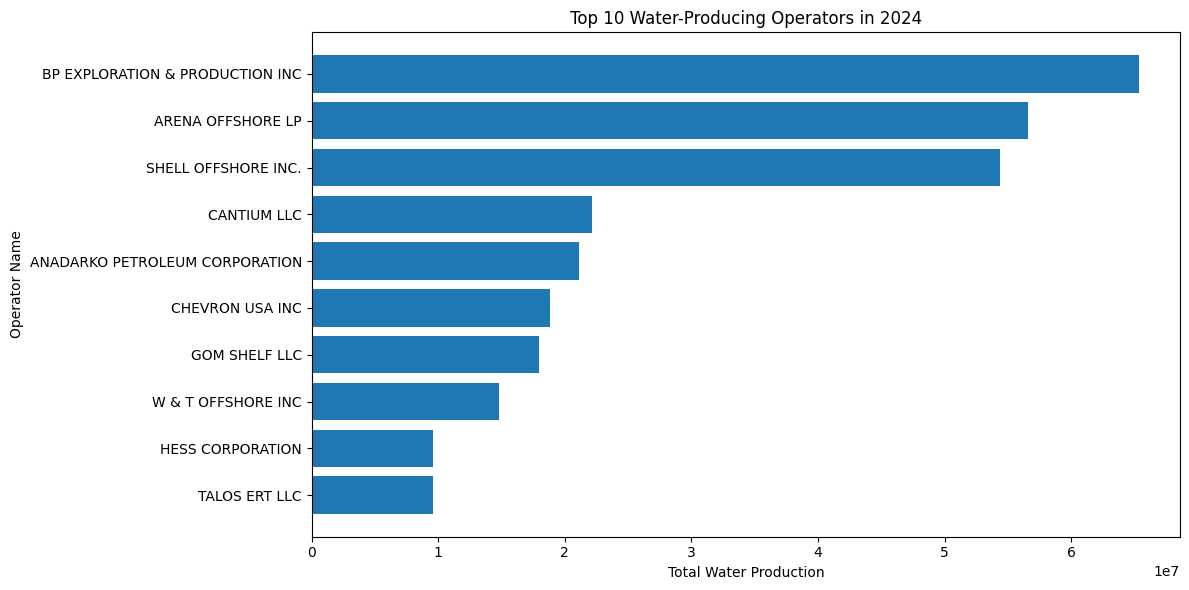

In [45]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_water_operators.index,
    top_10_water_operators["total_water"]
)

plt.title("Top 10 Water-Producing Operators in 2024")
plt.xlabel("Total Water Production")
plt.ylabel("Operator Name")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Interpretation:**

The analysis identifies the top 10 operators with the highest total water production in 2024.

The results show the distribution of water production among the leading operators. Operators with higher water production volumes contribute a larger share of the total produced water recorded in the dataset.

High water production can be associated with reservoir water production and may have implications for water handling, separation, treatment and disposal requirements.

This analysis provides an overview of water production across operators and helps identify those with the highest produced-water volumes during the year.

It is important to note that high water production alone does not necessarily indicate poor well performance. Further analysis of water cut, water-oil ratio (WOR), and individual well production trends would be required to understand the underlying production behaviour.

### Relationship Between Oil and Water Production

This section examines the relationship between oil and water production across individual wells. Aggregating production by API well number allows us to compare the total oil and water volumes recorded for each well.

In [46]:
well_production = df.groupby("api_well_number").agg(
    total_oil=("monthly_oil_volume", "sum"),
    total_gas=("monthly_gas_volume", "sum"),
    total_water=("monthly_water_volume", "sum")
)

well_production.head()

,total_oil,total_gas,total_water
api_well_number,,,
012032016500,0,1141,2
012032027100,0,0,0
012032029300,880,1892672,33725
012032030900,0,0,0
177000000600,0,81643,1698


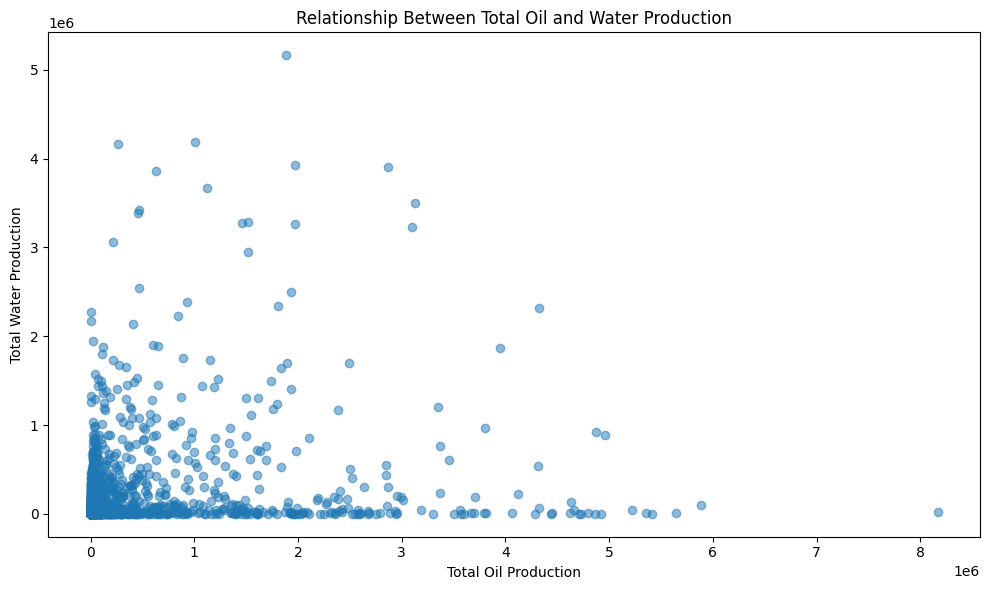

In [47]:
plt.figure(figsize=(10, 6))

plt.scatter(
    well_production["total_oil"],
    well_production["total_water"],
    alpha=0.5
)

plt.title("Relationship Between Total Oil and Water Production")
plt.xlabel("Total Oil Production")
plt.ylabel("Total Water Production")

plt.tight_layout()
plt.show()

### Oil and Water Production Correlation

Pearson correlation is used to measure the strength and direction of the linear relationship between total oil production and total water production across the wells.

The correlation coefficient ranges from -1 to +1:
- +1 indicates a perfect positive correlation.
- -1 indicates a perfect negative correlation.
- 0 indicates no linear correlation.

In [48]:
oil_water_correlation = well_production[
    ["total_oil", "total_water"]
].corr()

oil_water_correlation

,total_oil,total_water
total_oil,1.000000,0.282986
total_water,0.282986,1.000000


In [49]:
oil_water_corr_value = oil_water_correlation.loc[
    "total_oil", "total_water"
]

print("Oil-Water Correlation:", round(oil_water_corr_value, 4))

Oil-Water Correlation: 0.283


### Interpretation of Oil-Water Correlation

The Pearson correlation coefficient between total oil and total water production was approximately 0.2830, indicating a weak positive linear relationship across the wells analysed.

This suggests that wells with higher oil production may also record higher water production, although the relationship is relatively weak. Therefore, oil production alone does not adequately explain variations in water production.

Further investigation using well-specific production histories and water-oil ratios would provide additional insight into individual well performance.

### Oil and Gas Production Correlation

In [50]:
oil_gas_correlation = well_production[
    ["total_oil", "total_gas"]
].corr()

oil_gas_correlation

,total_oil,total_gas
total_oil,1.000000,0.646856
total_gas,0.646856,1.000000


In [51]:
oil_gas_corr_value = oil_gas_correlation.loc[
    "total_oil", "total_gas"
]

print("Oil-Gas Correlation:", round(oil_gas_corr_value, 4))

Oil-Gas Correlation: 0.6469


### Interpretation of Oil-Gas Correlation

The Pearson correlation coefficient between total oil and total gas production was approximately 0.6469, indicating a moderate positive linear relationship across the wells analysed.

This suggests that wells with higher oil production generally tend to record higher gas production. The relationship is stronger than the observed relationship between oil and water production.

However, correlation does not establish causation, and individual well characteristics and production conditions may influence these patterns.

### Comparison of Production Correlations

This section compares the correlation coefficients obtained for oil-water and oil-gas production across the wells.

The comparison helps identify which production variable has a stronger linear relationship with oil production.

### Comparison of Production Relationships

The correlation analysis shows that oil and gas production have a moderate positive relationship (0.6469), while oil and water production have a weak positive relationship (0.2830).

This indicates that oil production varies more closely with gas production than with water production across the wells analysed.

These findings provide insight into the production patterns in the dataset, although correlation alone cannot establish causal relationships.

## Well Production Analysis

This section examines production performance at the individual well level. Oil, gas, and water production volumes are aggregated by well to identify production patterns and compare the contribution of individual wells.

In [52]:
well_production["WOR"] = np.where(
    well_production["total_oil"] > 0,
    well_production["total_water"] / well_production["total_oil"],
    np.nan
)

well_production[["total_oil", "total_water", "WOR"]].head(10)

,total_oil,total_water,WOR
api_well_number,,,
012032016500,0,2,NaN
012032027100,0,0,NaN
012032029300,880,33725,38.323864
012032030900,0,0,NaN
177000000600,0,1698,NaN
177000026100,0,0,NaN
177000031300,0,0,NaN
177002006800,0,0,NaN
177002007100,0,0,NaN


In [53]:
top_10_wor_wells = well_production[
    well_production["WOR"].notna()
].sort_values(
    by="WOR",
    ascending=False
).head(10)

top_10_wor_wells[
    ["total_oil", "total_water", "WOR"]
]

,total_oil,total_water,WOR
api_well_number,,,
177064040900,1,9187,9187.000000
177244097401,22,57780,2626.363636
608174012603,5,8337,1667.400000
177154095000,16,20907,1306.687500
427114072200,137,123780,903.503650
177114035901,199,91302,458.804020
427114074200,1,342,342.000000
177114141101,4,1349,337.250000
177190096701,91,25982,285.516484


### Analysis of Wells with the Highest Water-Oil Ratios

The analysis identified the ten wells with the highest calculated Water-Oil Ratios (WOR) in 2024.

Well 177064040900 recorded the highest WOR of 9,187, producing 9,187 units of water against only 1 unit of oil.

However, extremely high WOR values should be interpreted cautiously, as wells with very low oil production can produce disproportionately high ratios.

These wells may require further investigation using their production histories and operational data to understand the factors contributing to their high water production relative to oil.

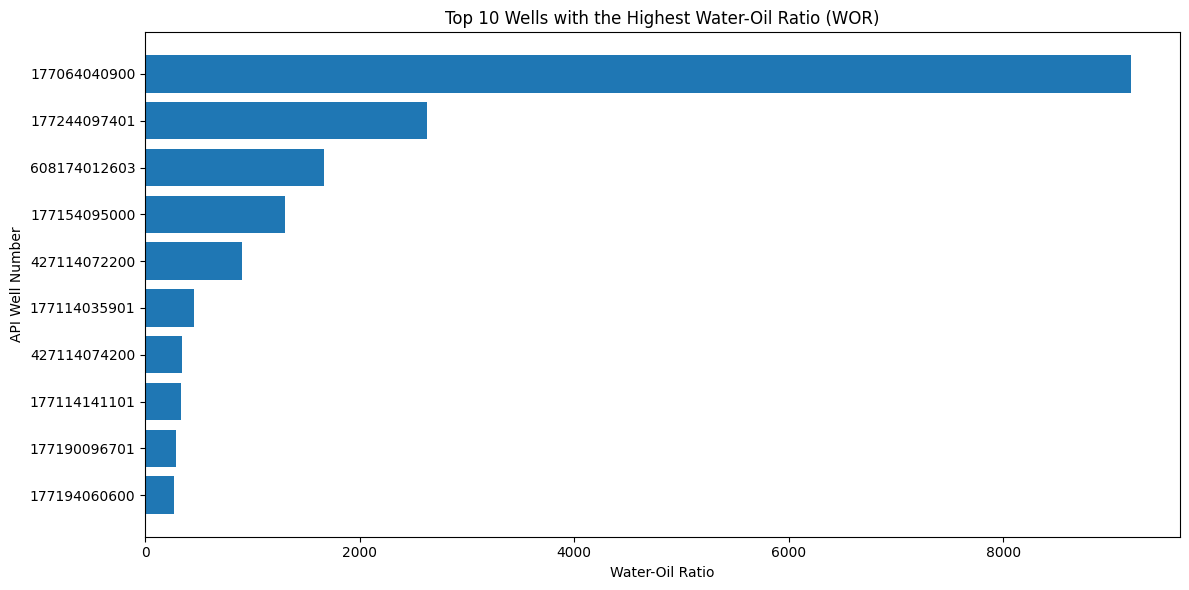

In [54]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_wor_wells.index.astype(str),
    top_10_wor_wells["WOR"]
)

plt.title("Top 10 Wells with the Highest Water-Oil Ratio (WOR)")
plt.xlabel("Water-Oil Ratio")
plt.ylabel("API Well Number")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [55]:
top_oil_wells_with_wor = well_production.sort_values(
    by="total_oil",
    ascending=False
).head(10)

top_oil_wells_with_wor[
    ["total_oil", "total_water", "WOR"]
]

,total_oil,total_water,WOR
api_well_number,,,
608174144500,8166097,18845,0.002308
608174101101,5882419,94864,0.016127
608054005400,5644063,9016,0.001597
608174133000,5414667,0,0.000000
608114070600,5350210,5443,0.001017
608124006001,5217804,39994,0.007665
608174132800,4957222,886268,0.178783
608174133900,4925348,2872,0.000583
608174119802,4875798,916738,0.188018


### Water-Oil Ratio Among the Top Oil-Producing Wells

The analysis of the ten highest oil-producing wells revealed generally low Water-Oil Ratios (WOR).

Well 608174144500 recorded the highest oil production of 8,166,097 units, with a WOR of approximately 0.0023.

Among these ten wells, well 608174119802 recorded the highest WOR of approximately 0.1880.

Two wells recorded zero water production during the period analysed.

The results highlight the importance of considering both production volumes and WOR when evaluating well performance. High WOR values should be interpreted alongside absolute oil and water production volumes.

## Key Findings and Observations

### 1. Monthly Production Trends

Oil and gas production showed variations throughout 2024. A notable decline was observed in September, while December recorded higher production volumes, with approximately 58.05 million units of oil and 60.41 million units of gas.

### 2. Operator Performance

SHELL OFFSHORE INC. recorded the highest total oil production of 171.70 million units and gas production of 167.43 million units.

BP EXPLORATION & PRODUCTION INC. recorded the highest water production of approximately 65.34 million units.

### 3. Well Production Performance

The highest oil-producing well was API 608174144500, with a total oil production of 8,166,097 units.

The analysis also showed differences in water production across individual wells, with some high-oil-producing wells recording relatively low water production.

### 4. Relationship Between Production Variables

The correlation analysis revealed:

- Oil and water production: 0.2830 (weak positive correlation).
- Oil and gas production: 0.6469 (moderate positive correlation).

Oil production therefore showed a stronger linear relationship with gas production than with water production.

### 5. Water-Oil Ratio Analysis

The highest calculated WOR was 9,187, recorded by well 177064040900. However, this well produced only one unit of oil.

In comparison, the ten highest oil-producing wells generally recorded much lower WOR values. This demonstrates the importance of considering absolute production volumes alongside WOR when evaluating well performance.

## Conclusion

This exploratory data analysis examined offshore oil and gas production records for 2024 using Python. The analysis involved data inspection, cleaning, quality assessment, aggregation, statistical analysis and visualisation.

The results revealed variations in monthly production, differences in production performance among operators and wells, and relationships between oil, gas and water production.

The correlation analysis showed a moderate positive relationship between oil and gas production and a weaker positive relationship between oil and water production. The Water-Oil Ratio analysis also demonstrated how individual well production profiles can differ significantly.

Overall, this project provided practical insight into how data analytics can support production monitoring, performance comparison and the identification of unusual production patterns in the oil and gas industry.

Further analysis incorporating well characteristics, reservoir properties and longer production histories could provide deeper insight into the factors influencing production performance.